# Plot Daily Profile

Plot one home's average hourly consumption for January-August 2013.

Open this notebook in `notebooks/M5/`. Run the cells in order. Saving again replaces this notebook's output files.


## Shared folder setup

In [1]:
from pathlib import Path
PROJECT_ROOT = Path("../..").resolve()
PROJECT_ROOT

WindowsPath('C:/Projects/Data mining project/household-energy-prediction')

## Read the M2 hourly file

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
hourly_path = PROJECT_ROOT / "data/pilot/hourly_sample.csv"
hourly = pd.read_csv(hourly_path)
hourly.head()

,LCLid,hour_start,kWh,n_valid,is_complete
0,MAC000414,2013-01-01 00:00:00+00:00,0.273,2,True
1,MAC000414,2013-01-01 01:00:00+00:00,0.193,2,True
2,MAC000414,2013-01-01 02:00:00+00:00,0.090,2,True
3,MAC000414,2013-01-01 03:00:00+00:00,0.091,2,True
4,MAC000414,2013-01-01 04:00:00+00:00,0.127,2,True


## Parse the needed columns

In [3]:
hourly["hour_start"] = pd.to_datetime(hourly["hour_start"], utc=True)
hourly["kWh"] = pd.to_numeric(hourly["kWh"])
hourly.dtypes

LCLid                          str
hour_start     datetime64[us, UTC]
kWh                        float64
n_valid                      int64
is_complete                   bool
dtype: object

## Select the same example home and TRAIN dates

In [4]:
sample_home = "MAC000414"
start = pd.Timestamp("2013-01-01", tz="UTC")
end = pd.Timestamp("2013-09-01", tz="UTC")
selected = hourly[(hourly["LCLid"] == sample_home) & (hourly["hour_start"] >= start) & (hourly["hour_start"] < end)]
selected.head()

,LCLid,hour_start,kWh,n_valid,is_complete
0,MAC000414,2013-01-01 00:00:00+00:00,0.273,2,True
1,MAC000414,2013-01-01 01:00:00+00:00,0.193,2,True
2,MAC000414,2013-01-01 02:00:00+00:00,0.090,2,True
3,MAC000414,2013-01-01 03:00:00+00:00,0.091,2,True
4,MAC000414,2013-01-01 04:00:00+00:00,0.127,2,True


## Make the full expected hourly grid

In [5]:
hours = pd.date_range(start, end, freq="h", inclusive="left")
values = selected.set_index("hour_start")["kWh"].reindex(hours)
len(values), values.isna().sum()

(5832, np.int64(75))

## Separate clock hour from date

In [6]:
profile_input = values.rename("kWh").to_frame()
profile_input["hour_of_day"] = profile_input.index.hour
profile_input.head()

,kWh,hour_of_day
2013-01-01 00:00:00+00:00,0.273,0
2013-01-01 01:00:00+00:00,0.193,1
2013-01-01 02:00:00+00:00,0.090,2
2013-01-01 03:00:00+00:00,0.091,3
2013-01-01 04:00:00+00:00,0.127,4


## Calculate the mean and available observations

In [7]:
profile = profile_input.groupby("hour_of_day")["kWh"].agg(mean_hourly_kwh="mean",
    available_observations="count")
profile = profile.reindex(range(24)).reset_index()
profile.insert(0, "LCLid", sample_home)
profile

,LCLid,hour_of_day,mean_hourly_kwh,available_observations
0,MAC000414,0,0.253243,239
1,MAC000414,1,0.253213,240
2,MAC000414,2,0.236649,239
3,MAC000414,3,0.244388,240
4,MAC000414,4,0.212504,240
5,MAC000414,5,0.179725,240
6,MAC000414,6,0.178075,240
7,MAC000414,7,0.169071,240
8,MAC000414,8,0.180746,240
9,MAC000414,9,0.257458,240


## Show coverage alongside the mean

In [8]:
days = (end - start).days
coverage = profile[["LCLid", "hour_of_day", "available_observations"]].copy()
coverage["expected_observations"] = days
coverage["missing_observations"] = days - coverage["available_observations"]
coverage

,LCLid,hour_of_day,available_observations,expected_observations,missing_observations
0,MAC000414,0,239,243,4
1,MAC000414,1,240,243,3
2,MAC000414,2,239,243,4
3,MAC000414,3,240,243,3
4,MAC000414,4,240,243,3
5,MAC000414,5,240,243,3
6,MAC000414,6,240,243,3
7,MAC000414,7,240,243,3
8,MAC000414,8,240,243,3
9,MAC000414,9,240,243,3


## Read the range of available days

In [9]:
min_obs = profile["available_observations"].min()
max_obs = profile["available_observations"].max()
min_obs, max_obs, days

(np.int64(239), np.int64(240), 243)

## Chart 3: average daily profile

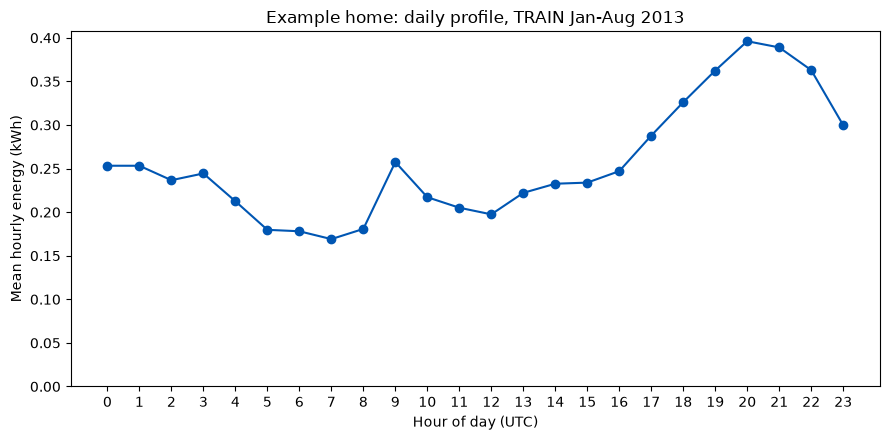

In [10]:
profile_fig, profile_ax = plt.subplots(figsize=(9, 4.5))
profile_ax.plot(profile["hour_of_day"], profile["mean_hourly_kwh"], marker="o", color="#0056b3")
profile_ax.set(title="Example home: daily profile, TRAIN Jan-Aug 2013",
    xlabel="Hour of day (UTC)", ylabel="Mean hourly energy (kWh)")
profile_ax.set_xticks(range(24))
profile_ax.set_ylim(bottom=0)
profile_fig.tight_layout()
plt.show()

## Find the highest and lowest mean hours

In [11]:
peak = profile.loc[profile["mean_hourly_kwh"].idxmax()]
low = profile.loc[profile["mean_hourly_kwh"].idxmin()]
profile.loc[[low.name, peak.name], ["hour_of_day", "mean_hourly_kwh", "available_observations"]]

,hour_of_day,mean_hourly_kwh,available_observations
7,7,0.169071,240
20,20,0.396063,240


## Choose the output folder

In [12]:
output_dir = PROJECT_ROOT / 'data/processed'
output_dir.mkdir(parents=True, exist_ok=True)
output_dir

WindowsPath('C:/Projects/Data mining project/household-energy-prediction/data/processed')

## Save the four-column profile format

In [13]:
profile_path = output_dir / "daily_profile_sample.csv"
profile.to_csv(profile_path, index=False)
profile_path

WindowsPath('C:/Projects/Data mining project/household-energy-prediction/data/processed/daily_profile_sample.csv')

## Save the profile chart

In [14]:
chart_path = PROJECT_ROOT / "figures" / "daily_profile_sample.png"
profile_fig.savefig(chart_path, dpi=150)
chart_path

WindowsPath('C:/Projects/Data mining project/household-energy-prediction/figures/daily_profile_sample.png')

## Save the hourly coverage table

In [15]:
coverage_path = output_dir / "daily_profile_coverage_sample.csv"
coverage.to_csv(coverage_path, index=False)
coverage_path

WindowsPath('C:/Projects/Data mining project/household-energy-prediction/data/processed/daily_profile_coverage_sample.csv')

## Prepare a scope and coverage caption

In [16]:
caption = (
    f"Home {sample_home}, Jan-Aug 2013. Mean kWh for each hour of the day. "
    f"Each hour uses {min_obs}-{max_obs} available days out of {days}. Missing hours are excluded."
)
caption

'Home MAC000414, Jan-Aug 2013. Mean kWh for each hour of the day. Each hour uses 239-240 available days out of 243. Missing hours are excluded.'

## Save the profile notes

In [17]:
notes_path = PROJECT_ROOT / "figures" / "daily_profile_notes_sample.md"
notes = "# M5 daily profile notes\n\n" + caption + "\n\nThe profile shows one home during the training period.\n"
notes_path.write_text(notes, encoding="utf-8")
notes_path

WindowsPath('C:/Projects/Data mining project/household-energy-prediction/figures/daily_profile_notes_sample.md')

## Open the saved profile

In [18]:
pd.read_csv(profile_path)

,LCLid,hour_of_day,mean_hourly_kwh,available_observations
0,MAC000414,0,0.253243,239
1,MAC000414,1,0.253213,240
2,MAC000414,2,0.236649,239
3,MAC000414,3,0.244388,240
4,MAC000414,4,0.212504,240
5,MAC000414,5,0.179725,240
6,MAC000414,6,0.178075,240
7,MAC000414,7,0.169071,240
8,MAC000414,8,0.180746,240
9,MAC000414,9,0.257458,240
